In [181]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)


In [182]:
# Reading the saved data pickle file
# rng = pd.date_range('2019-02-24', periods=661, freq='T')
# df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)
df_companies=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/press_release_companies_statistics.pkl', compression=None)

In [183]:
df_companies

,companies,count
0,MMM,92
1,ABT,74
2,ABBV,118
3,ABMD,26
4,ACN,151
...,...,...
500,YUM,50
501,ZBRA,29
502,ZBH,19
503,ZION,21


In [184]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"]#.apply(np.int)
df["vix_ln_return"]=np.log(df["vix"]/df["vix"].shift(1))
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
# df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

In [185]:
df

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,vix,vix_ln_return,sentiment_ewm,date
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...,1.0,0.015,0.879,0.106,87.603306,12.396694,15.960000,NaN,87.603306,2019-09-25
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre...",1.0,0.022,0.859,0.118,84.285714,15.714286,16.070000,0.006869,85.865520,2019-09-26
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...,0.9998,0.033,0.862,0.105,76.086957,23.913043,17.219999,0.069117,82.290879,2019-09-27
2019-09-30,16.240000,16.240000,"ParTech, Inc. completed the acquisition of ass...",1.0,0.024,0.849,0.127,84.105960,15.894040,16.240000,-0.058594,82.811429,2019-09-30
2019-10-01,18.559999,18.559999,"Accenture plc Presents at All Day DevOps, Nov-...",0.9999,0.021,0.901,0.078,78.787879,21.212121,18.559999,0.133531,81.846518,2019-10-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,0.9999,0.013,0.848,0.138,91.390728,8.609272,16.170000,-0.000618,88.107165,2021-07-12
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,1.0,0.011,0.843,0.146,92.993631,7.006369,17.120001,0.057090,88.551389,2021-07-13
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,0.9999,0.01,0.874,0.116,92.063492,7.936508,16.330000,-0.047244,88.870672,2021-07-14
2021-07-15,17.010000,17.010000,Air Products Declares Quarterly Dividend. LEHI...,1.0,0.016,0.817,0.166,91.208791,8.791209,17.010000,0.040797,89.083228,2021-07-15


<AxesSubplot:ylabel='Frequency'>

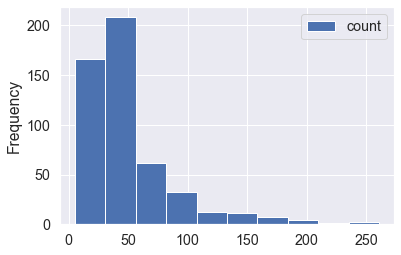

In [186]:
df_companies.plot(kind="hist")

In [202]:
df_companies

,companies,count
0,MMM,92
1,ABT,74
2,ABBV,118
3,ABMD,26
4,ACN,151
...,...,...
500,YUM,50
501,ZBRA,29
502,ZBH,19
503,ZION,21


In [208]:
df_companies = df_companies.rename(columns={"companies": "Ticker", "count": "PressReleaseCount"})

In [209]:
df_companies

,Ticker,PressReleaseCount
0,MMM,92
1,ABT,74
2,ABBV,118
3,ABMD,26
4,ACN,151
...,...,...
500,YUM,50
501,ZBRA,29
502,ZBH,19
503,ZION,21




In [210]:
# cols = (df_companies[["companies", "count"]]
#         .groupby("companies")
#         .mean()
#         .sort_values(by="count", ascending=False)[:150].index)
# best_features = df_companies.loc[feature_importance_df.Feature.isin(cols)]

plt.figure(figsize=(20,150))
chart=sns.barplot(x="PressReleaseCount", y="Ticker", data=df_companies.sort_values(by="PressReleaseCount",ascending=False))
chart.bar_label(chart.containers[0])
plt.title('S&P500 Companies by Press Release Count')
plt.tight_layout()
plt.savefig('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/S&P500 Companies by Press Release Count.png')

In [211]:
df_companies_mkp=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/S&P500CompaniesByMarketCap.csv')

In [212]:
df_companies_mkp

,Rank,Ticker,Company,Industry,Market Cap ($M),MarketCapMillions
0,1,AAPL,Apple,Consumer Electronics,"$ 2,236,010",2236010.0
1,2,MSFT,Microsoft,Software – Infrastructure,"$ 1,838,040",1838040.0
2,3,AMZN,Amazon.com,Internet Retail,"$ 1,646,130",1646130.0
3,4,GOOG,Alphabet,Internet Content & Information,"$ 1,427,450",1427450.0
4,5,GOOGL,Alphabet,Internet Content & Information,"$ 1,426,070",1426070.0
...,...,...,...,...,...,...
499,500,HFC,HollyFrontier,Oil & Gas Refining & Marketing,"$ 5,403",5403.0
500,501,UNM,Unum,Insurance – Life,"$ 5,204",5204.0
501,502,FLS,Flowserve,Specialty Industrial Machinery,"$ 5,102",5102.0
502,503,XRX,Xerox Holdings,Information Technology Services,"$ 4,750",4750.0


In [213]:
type(df_companies_mkp["MarketCapMillions"])

pandas.core.series.Series

In [214]:
df_companies_mkp = df_companies_mkp#.loc[1:3]#].Company.array
df_companies_mkp=df_companies_mkp[["Ticker", "Industry", "MarketCapMillions"]]

In [215]:
type(pd.to_numeric(df_companies_mkp['MarketCapMillions']))

pandas.core.series.Series

In [216]:
df_companies_mkp

,Ticker,Industry,MarketCapMillions
0,AAPL,Consumer Electronics,2236010.0
1,MSFT,Software – Infrastructure,1838040.0
2,AMZN,Internet Retail,1646130.0
3,GOOG,Internet Content & Information,1427450.0
4,GOOGL,Internet Content & Information,1426070.0
...,...,...,...
499,HFC,Oil & Gas Refining & Marketing,5403.0
500,UNM,Insurance – Life,5204.0
501,FLS,Specialty Industrial Machinery,5102.0
502,XRX,Information Technology Services,4750.0


In [217]:
import plotly.express as px
import numpy as np
fig = px.treemap(df_companies_mkp, path=[px.Constant("MarketCapMillions"), 'Industry', 'Ticker'], values='MarketCapMillions',
                  color='MarketCapMillions', hover_data=['MarketCapMillions'],
                  color_continuous_scale='RdBu')
                  #color_continuous_midpoint=np.average(df_companies_mkp['MarketCapMillions'], weights=df_companies_mkp['MarketCapMillions']))
fig.update_layout(margin = dict(t=100, l=50, r=50, b=50))
fig.show()

In [218]:
df_companies

,Ticker,PressReleaseCount
0,MMM,92
1,ABT,74
2,ABBV,118
3,ABMD,26
4,ACN,151
...,...,...
500,YUM,50
501,ZBRA,29
502,ZBH,19
503,ZION,21


In [220]:
import plotly.express as px
import numpy as np
fig = px.treemap(df_companies, path=[px.Constant("PressReleaseCount"), 'Ticker'], values='PressReleaseCount',
                  color='PressReleaseCount', hover_data=['PressReleaseCount'],
                  color_continuous_scale='RdBu')
                  #color_continuous_midpoint=np.average(df_companies_mkp['MarketCapMillions'], weights=df_companies_mkp['MarketCapMillions']))
fig.update_layout(margin = dict(t=100, l=50, r=50, b=50))
fig.show()

In [ ]:
import plotly.express as px
import numpy as np
df = px.data.gapminder().query("year == 2007")
print(df)
fig = px.treemap(df, path=[px.Constant("world"), 'continent', 'country'], values='pop',
                  color='lifeExp', hover_data=['iso_alpha'],
                  color_continuous_scale='RdBu',
                  color_continuous_midpoint=np.average(df['lifeExp'], weights=df['pop']))
fig.update_layout(margin = dict(t=50, l=25, r=25, b=25))
fig.show()

                 country continent  year  lifeExp       pop     gdpPercap  \
11           Afghanistan      Asia  2007   43.828  31889923    974.580338   
23               Albania    Europe  2007   76.423   3600523   5937.029526   
35               Algeria    Africa  2007   72.301  33333216   6223.367465   
47                Angola    Africa  2007   42.731  12420476   4797.231267   
59             Argentina  Americas  2007   75.320  40301927  12779.379640   
...                  ...       ...   ...      ...       ...           ...   
1655             Vietnam      Asia  2007   74.249  85262356   2441.576404   
1667  West Bank and Gaza      Asia  2007   73.422   4018332   3025.349798   
1679         Yemen, Rep.      Asia  2007   62.698  22211743   2280.769906   
1691              Zambia    Africa  2007   42.384  11746035   1271.211593   
1703            Zimbabwe    Africa  2007   43.487  12311143    469.709298   

     iso_alpha  iso_num  
11         AFG        4  
23         ALB        8